In [1]:
# package load 
import numpy as np 
import matplotlib.pyplot as plt 


# load data
import rdata
converted = rdata.read_rda(rdata.TESTDATA_PATH / "/Users/alexander/Chalmers/MVEX11-25-18/ERIKA.rds")

/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/rdata/parser/_parser.py:1217: UserWarning: Unknown file type: assumed RDS
  warnings.warn("Unknown file type: assumed RDS")  # noqa: B028
/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/rdata/parser/_parser.py:1220: UserWarning: Wrong extension .rda for file in RDS format
  warnings.warn(f"Wrong extension {extension} for file in RDS format")  # noqa: B028
/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/rdata/conversion/_conversion.py:856: UserWarning: Missing constructor for R class "unitname". The underlying R object is returned instead.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/rdata/conversion/_conversion.py:856: UserWarning: Missing constructor for R class "owin". The underlying R object is returned instead.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.10/lib/python3

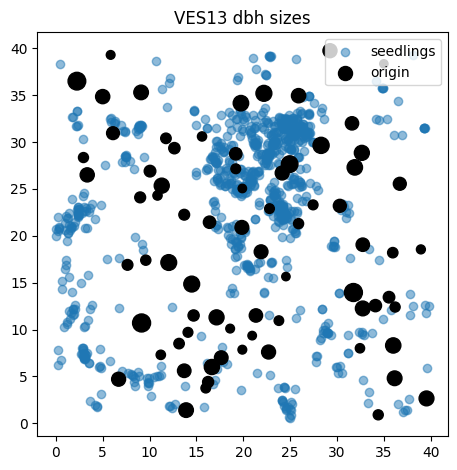

In [2]:
import matplotlib.pyplot as plt 
converted.keys()  # all data names 

converted['VES13'].items()  # what every data name contains 
A = [converted['VES13']['large']['x'], converted['VES13']['large']['y'], converted['VES13']['large']['dbh']]

fig, ax = plt.subplots()
ax.scatter(converted['VES13']['small']['x'], converted['VES13']['small']['y'], alpha=0.5, label='seedlings')
ax.scatter(A[0], A[1], s=A[2]*5, color='black', label='origin')

ax.set_title('VES13 dbh sizes')
ax.legend(loc='best')
ax.set_aspect('equal')
fig.tight_layout()

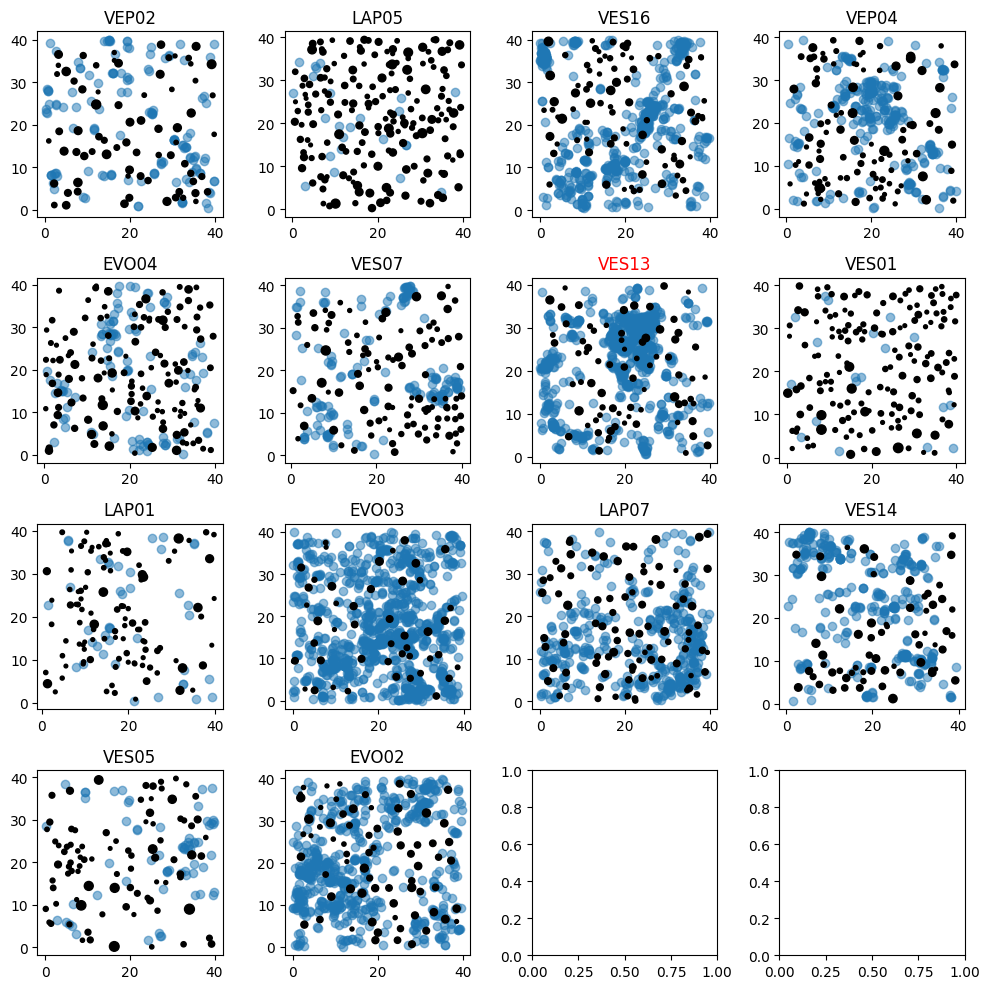

In [3]:
n = len(converted.keys())

fig2, ax2 = plt.subplots(4,4, figsize=(10,10))

for i ,name in enumerate(converted.keys()):
    
    c = divmod(i,4)
    # print(i,name)
    dbh = [converted[name]['large']['x'], converted[name]['large']['y'], converted[name]['large']['dbh']]
    
    ax2[c].scatter(converted[name]['small']['x'], converted[name]['small']['y'], alpha=.5)
    ax2[c].scatter(dbh[0], dbh[1], s=dbh[2], color='black')
    ax2[c].set_title(f'{name}')  
    if name == 'VES13':
        ax2[c].set_title(f'{name}',color='red')
    
converted['VES13'].keys()
fig2.tight_layout()

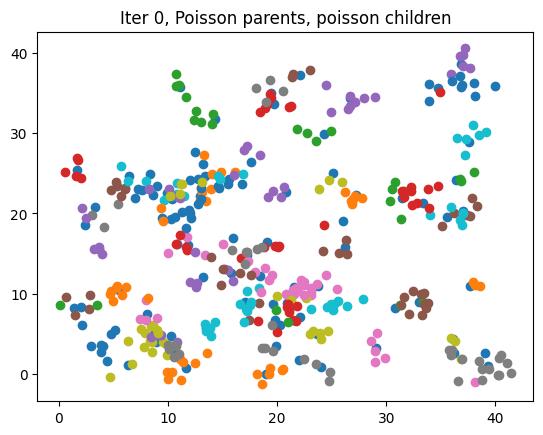

In [8]:
# start code for iter_poisson 
# Iteration 0, get 10% of children
# variables
# xy_parent:                    all parent points from that iter 
# x_history, y_history:         stores x,y position from generated children 

import matplotlib.pyplot as plt 
import numpy as np 

rng = np.random.default_rng()

# xy_c = np.array([converted['VES13']['small']['x'], converted['VES13']['small']['y']])
xy_p = np.array([converted['VES13']['large']['x'], converted['VES13']['large']['y']])
# xy_child = np.vstack([xy_c[0], xy_c[1]]).T
xy_parent = np.vstack([xy_p[0], xy_p[1]]).T  # combine points into pattern we use 



# math parameter 
size = xy_p.shape[1]  # self contained data, just load data into xy_p 
n_parent = size  # New parent size inspired from previous 
size = rng.poisson(n_parent)  # random new n_parents 
lam = 5
n_children = rng.poisson(lam=lam, size=size)  # random children per parent, after lam number
save_percent = 0.1 

# Create new parents, iter0 from poisson(size parent points from data)
x_parent = rng.uniform(0,40, size)  # becomes new_ x,y later 
y_parent = rng.uniform(0,40, size)

plt.scatter(x_parent, y_parent)

# log of all child points, not ideal but works. Addition save all points, remove for only childs!
x_history = [x_parent]  
y_history = [y_parent]


for i in range(size):
    x_child = rng.normal(x_parent[i], size=n_children[i])
    y_child = rng.normal(y_parent[i], size=n_children[i])
    # print(len(x_child), len(y_child))
    x_history.append(x_child)
    y_history.append(y_child)
    plt.scatter(x_child, y_child)
    
plt.title('Iter 0, Poisson parents, poisson children');


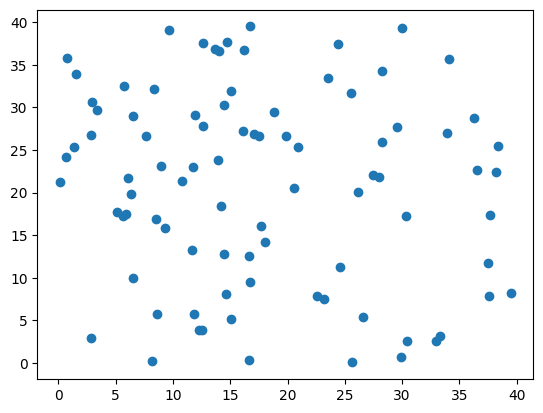

In [9]:
## loads rng  start here 
import numpy as np 
import matplotlib.pyplot as plt 
rng = np.random.default_rng()

n_parent = len(xy_parent)  # original parent have 74
size = rng.poisson(n_parent)  # random new n_parents 
lam = 5
n_children = rng.poisson(lam=lam, size=size)  # random children per parent, after lam number

len(n_children), n_children

# set parent location 
x_parent = rng.uniform(0,40, size)
y_parent = rng.uniform(0,40, size)

plt.scatter(x_parent, y_parent)

In [7]:
# Example edge correction > second step 
import numpy as np 
# variables
# xy_parent:                    all parent points from that iter 
# x_history, y_history:         stores x,y position from generated children 
# 
import matplotlib.pyplot as plt 
from matplotlib.pyplot import figure
import matplotlib.pyplot as plt
import matplotlib.colors as clrs

# xy_c = np.array([converted['VES13']['small']['x'], converted['VES13']['small']['y']])
xy_p = np.array([converted['VES13']['large']['x'], converted['VES13']['large']['y']])
# xy_child = np.vstack([xy_c[0], xy_c[1]]).T
xy_parent = np.vstack([xy_p[0], xy_p[1]]).T  # combine points into pattern we use 


# math parameter 
size = xy_p.shape[1]  # self contained data, just load data into xy_p 
n_parent = size  # New parent size inspired from previous 
size = rng.poisson(n_parent)  # random new n_parents 
lam = 5
n_children = rng.poisson(lam=lam, size=size)  # random children per parent, after lam number
save_percent = 0.1 

# Create new parents, iter0 from poisson(size parent points from data)
x_parent = rng.uniform(0,40, size)  # becomes new_ x,y later 
y_parent = rng.uniform(0,40, size)

# plt.scatter(x_parent, y_parent)

# log of all child points, not ideal but works. Addition save all points, remove for only childs!
x_history = [x_parent]  
y_history = [y_parent]



74
[68  7  4]


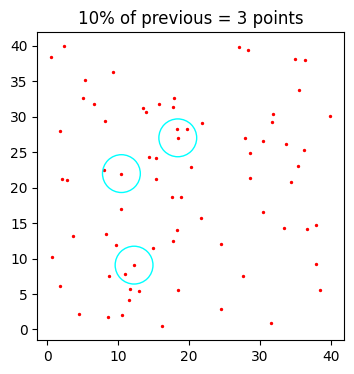

3


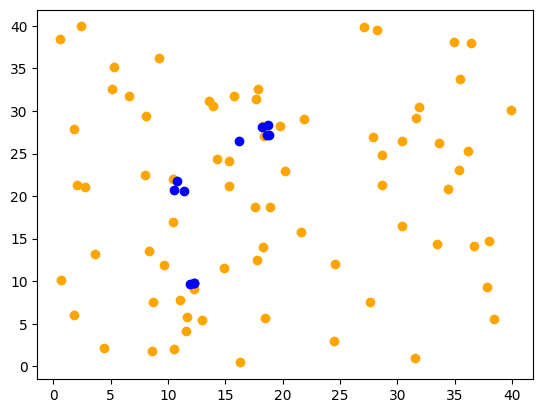

In [ ]:
## Ändra iterativ till att ta random föräldrar
from numpy import linalg as LA

def iter_poisson_unif(outx, outy, lam=5, r_survive=3, iter=0):
    all_points = np.vstack([outx, outy]).T
    # outx = np.array(outx)
    # outy = np.array(outy)
    x_history=[outx]
    y_history=[outy]

    r_density_survive = r_survive  # default 3 

    count_all = np.array([np.sum(LA.norm((all_points - origin_p), axis=1) <= r_density_survive) for origin_p in all_points])  # take points that survive 
    count_all = count_all - 1  # exclude self
    print(all_points.shape[0]) # should grow, do point accounting
    # count_survive = all_points.shape[0]*0.1  # antal % som överlever
    # survive_point = heapq.nlargest(int(count_survive), enumerate(count_all.astype(int)), key=lambda x: x[1])
    # index=np.array(survive_point)[:,0]
    
    size_unif = int(np.array(outx).shape[0]*0.05)
    index = np.random.randint(0,all_points.shape[0], size=size_unif)  # 
    print(index)



    # plt.figure(figsize=(4, 4))
    # plt.scatter(all_points[:, 0], all_points[:, 1], color='red', marker='o', s=2)

    fig = plt.gcf()
    ax = fig.gca()

    for i in index:
        circle2 = plt.Circle(all_points[i], r_density_survive/3, color='cyan', lw=1, fill=False)
        ax.add_patch(circle2)

    ax.set_aspect('equal', 'box')
    ax.set_title(f'10% of previous = {index.shape[0]} points')  # use to deduce what lambda should be 

    # plt.show() # take away 
    
    # broadcast the new points into next model 
    x_new_10_parent = [all_points[index][:,0]]  # picks the index points to generate new children
    y_new_10_parent = [all_points[index][:,1]]

    outx = np.concatenate(x_new_10_parent).ravel().tolist()
    outy = np.concatenate(y_new_10_parent).ravel().tolist()
    new_x = np.array(outx)
    new_y = np.array(outy)
    
    # plt.scatter(all_points[:,0], all_points[:,1], color='orange', label='previous') # take away

    # print(new_y.shape[0]) # take away comments 
    n_children = rng.poisson(lam=lam, size=new_y.shape[0])  # lam = 5 change above, gets new children for new parents 
    for i in range(new_y.shape[0]):
        x_child = rng.normal(new_x[i], size=n_children[i])
        y_child = rng.normal(new_y[i], size=n_children[i])
        x_history.append(x_child)  # add the children to x_history/y_history
        y_history.append(y_child)
        # if i == 0:
        #     plt.scatter(x_child, y_child, color='blue', label='new generated')  # only one legend
        # else:
        #     plt.scatter(x_child, y_child, color='blue')

    # plt.title(f'Iterative, step {iter}')
    # plt.legend(loc='best')
    
    outx = np.concatenate(x_history).ravel().tolist() # special way to get a list from array
    outy = np.concatenate(y_history).ravel().tolist()
    
    # remove 
    # plt.savefig(f'/Users/alexander/Chalmers/MVEX11-25-18/python-fig/uinf-iterative{iter}-model.png', format='png', bbox_inches='tight')
    # fig.savefig(f'/Users/alexander/Chalmers/MVEX11-25-18/python-fig/uinf-inspiration{iter}-iterative.png', format='png', bbox_inches='tight')  # prior inspiration 
    
    return outx, outy


outx0 = np.concatenate(x_history).ravel().tolist() # special way to get a list from array
outy0 = np.concatenate(y_history).ravel().tolist()
outx1, outy1 = iter_poisson_unif(outx0, outy0, r_survive=8, iter=1)


74
[69 12  4]


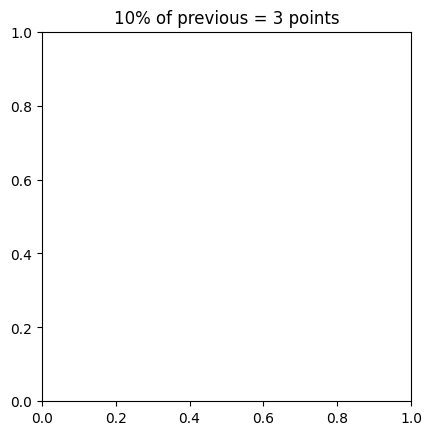

In [46]:
## Ändra iterativ till att ta random föräldrar
from numpy import linalg as LA

def iter_poisson_unif_pic(outx, outy, lam=5, r_survive=3, iter=0):
    all_points = np.vstack([outx, outy]).T
    # outx = np.array(outx)
    # outy = np.array(outy)
    x_history=[outx]
    y_history=[outy]

    r_density_survive = r_survive  # default 3 

    count_all = np.array([np.sum(LA.norm((all_points - origin_p), axis=1) <= r_density_survive) for origin_p in all_points])  # take points that survive 
    count_all = count_all - 1  # exclude self
    print(all_points.shape[0]) # should grow, do point accounting
    # count_survive = all_points.shape[0]*0.1  # antal % som överlever
    # survive_point = heapq.nlargest(int(count_survive), enumerate(count_all.astype(int)), key=lambda x: x[1])
    # index=np.array(survive_point)[:,0]
    
    size_unif = int(np.array(outx).shape[0]*0.05)
    index = np.random.randint(0,all_points.shape[0], size=size_unif)  # 
    print(index)



    plt.figure(figsize=(4, 4))
    plt.scatter(all_points[:, 0], all_points[:, 1], color='red', marker='o', s=2)

    fig = plt.gcf()
    ax = fig.gca()

    for i in index:
        circle2 = plt.Circle(all_points[i], r_density_survive/3, color='cyan', lw=1, fill=False)
        ax.add_patch(circle2)

    ax.set_aspect('equal', 'box')
    ax.set_title(f'10% of previous = {index.shape[0]} points')  # use to deduce what lambda should be 

    plt.show() # take away 
    
    # broadcast the new points into next model 
    x_new_10_parent = [all_points[index][:,0]]  # picks the index points to generate new children
    y_new_10_parent = [all_points[index][:,1]]

    outx = np.concatenate(x_new_10_parent).ravel().tolist()
    outy = np.concatenate(y_new_10_parent).ravel().tolist()
    new_x = np.array(outx)
    new_y = np.array(outy)
    if iter == 0:
        plt.scatter(all_points[:,0], all_points[:,1], color='orange', label=fr'$X^{{({iter})}}$') # take away    
    else:
        plt.scatter(all_points[:,0], all_points[:,1], color='orange', label=fr'$X^{{({iter})}}$') # take away

    print(new_y.shape[0]) # take away comments 
    n_children = rng.poisson(lam=lam, size=new_y.shape[0])  # lam = 5 change above, gets new children for new parents 
    for i in range(new_y.shape[0]):
        x_child = rng.normal(new_x[i], size=n_children[i])
        y_child = rng.normal(new_y[i], size=n_children[i])
        x_history.append(x_child)  # add the children to x_history/y_history
        y_history.append(y_child)
        if i == 0:
            plt.scatter(x_child, y_child, color='blue', label=fr'$X^{{({iter+1})}}$') # one legend 
        else:
            plt.scatter(x_child, y_child, color='blue')

    # plt.title(f'Iterative, step {iter+1}')
    plt.legend(loc='lower left', fontsize=14, frameon=True, edgecolor='black', facecolor='white')
    plt.xticks([])  # removes x-axis ticks and labels
    plt.yticks([])  # removes y-axis ticks and labels
    # plt.axis('off')
    # plt.legend(loc='lower left', fontsize=14)
    
    outx = np.concatenate(x_history).ravel().tolist() # special way to get a list from array
    outy = np.concatenate(y_history).ravel().tolist()
    
    # remove 
    plt.savefig(f'/Users/alexander/Chalmers/MVEX11-25-18/python-fig/uinf-iterative_7may{iter}-model.png', format='png', bbox_inches='tight')
    # fig.savefig(f'/Users/alexander/Chalmers/MVEX11-25-18/python-fig/uinf-inspiration_7may{iter}-iterative.png', format='png', bbox_inches='tight')  # prior inspiration 
    
    return outx, outy


outx0 = np.concatenate(x_history).ravel().tolist() # special way to get a list from array
outy0 = np.concatenate(y_history).ravel().tolist()
outx1, outy1 = iter_poisson_unif(outx0, outy0, r_survive=8, iter=1)

74
[71 69 19]


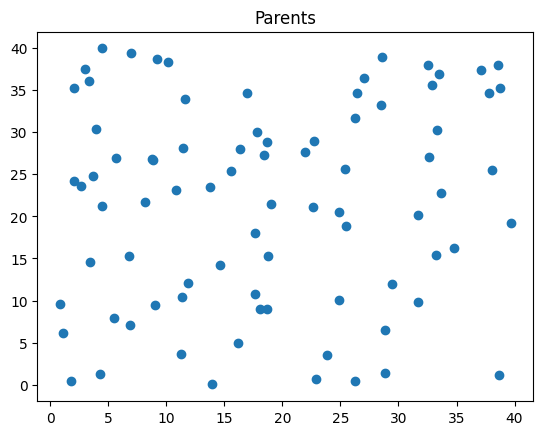

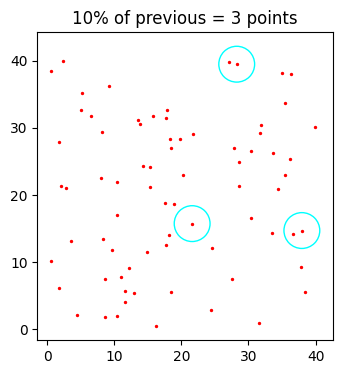

3
87
[37 31 51 10]


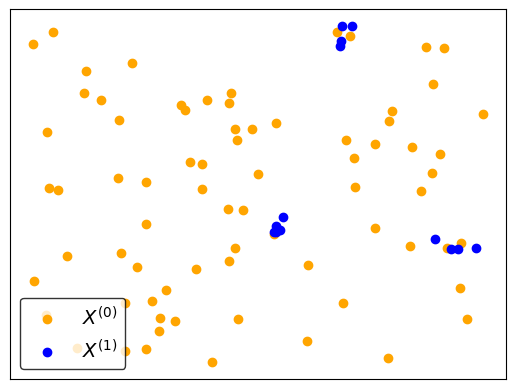

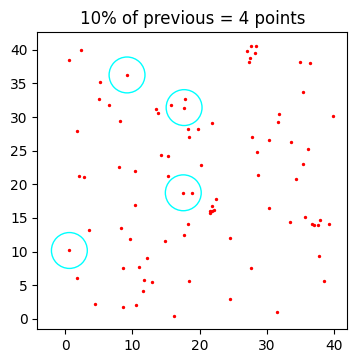

4
107
[96 19 64  4 22]


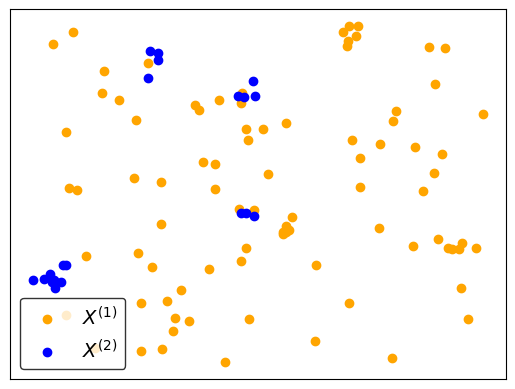

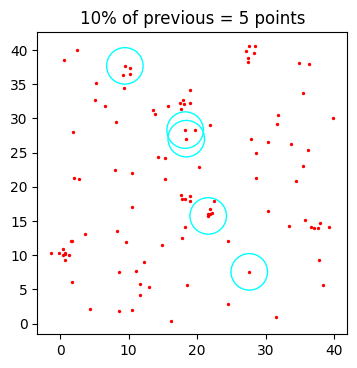

5
139
[129  67 112 121  21  78]


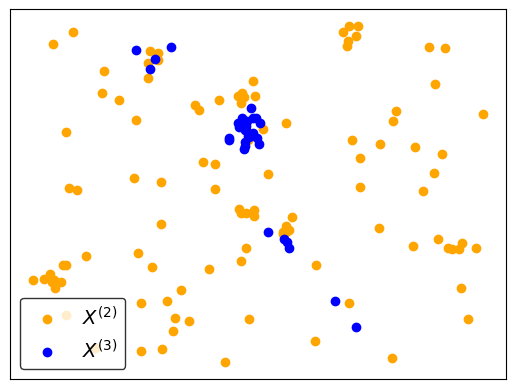

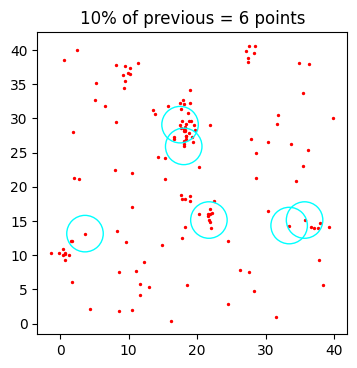

6
162
[ 19  81 130 105  43  71 148  97]


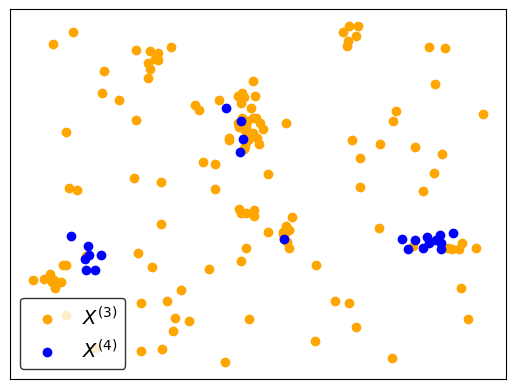

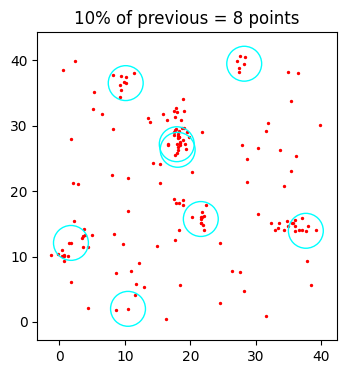

8
203
[ 92 173  70  35 178 194 148 119  69  26]


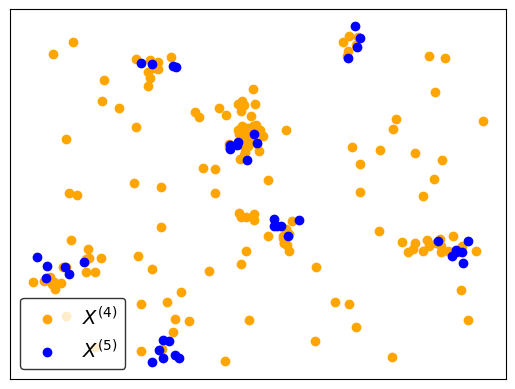

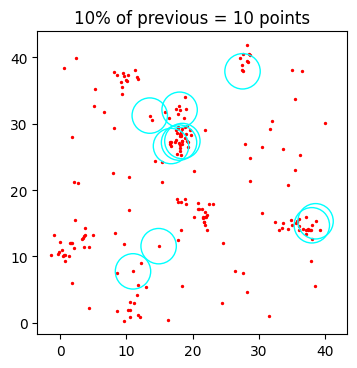

10
245
[ 45   2  96 237 158  71 225 170 164  27   1 222]


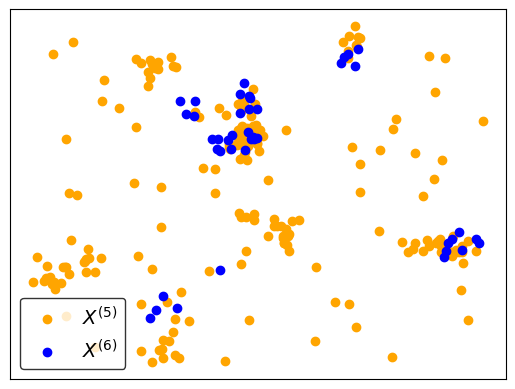

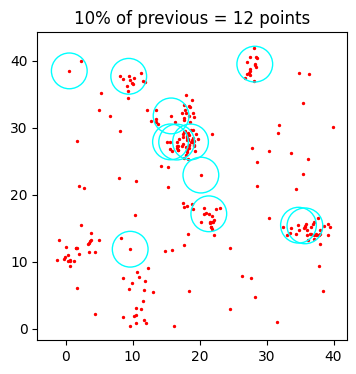

12
308
[157  34 117  42 152 222 277 164 161  35 187  83 236 113 287]


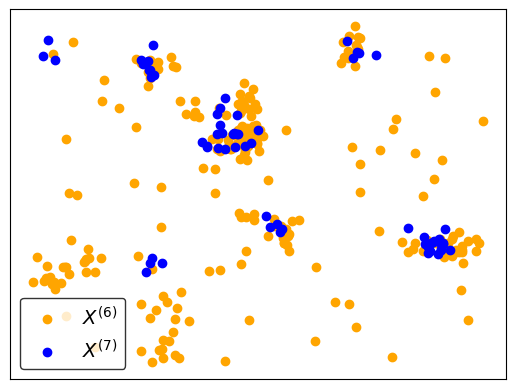

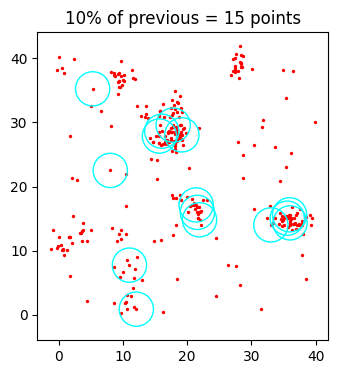

15
369
[ 31  54  57  56 358 114  45 105 198 336 135  93  43 333  87  14 237  52]


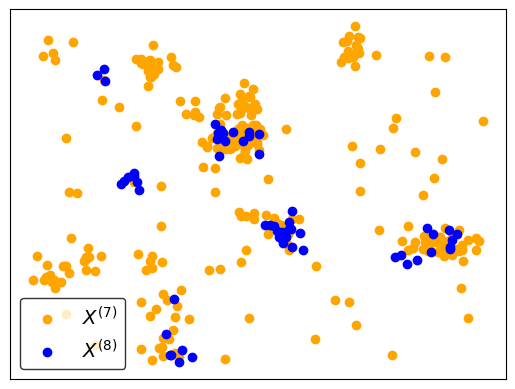

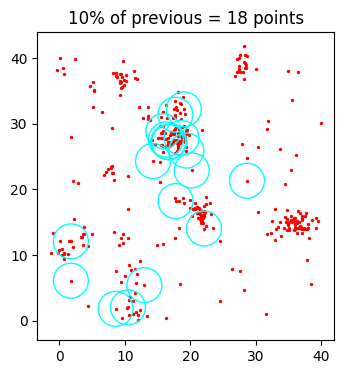

18
449
[351  19  37 233 119 228 125 158 441 326 381 138 305  43 221 393 118 112
 438 216 224 227]


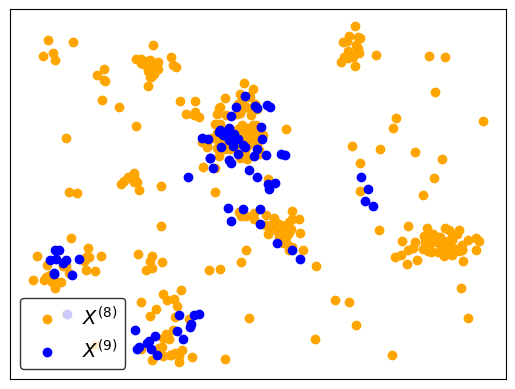

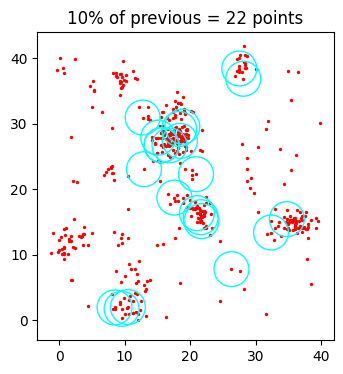

22
562
[327  99 472 261 291 465 124 440 207  37 117 545 517 210 148 301 279  65
 318 473  97 222 411 341 177 315  27 197]


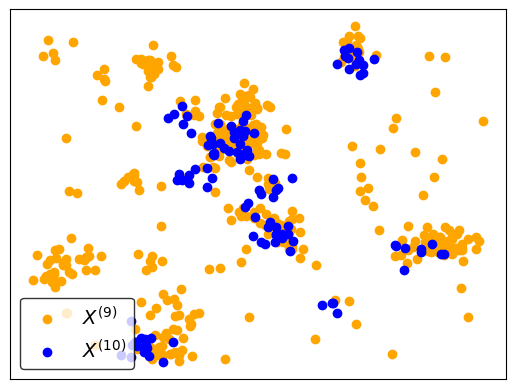

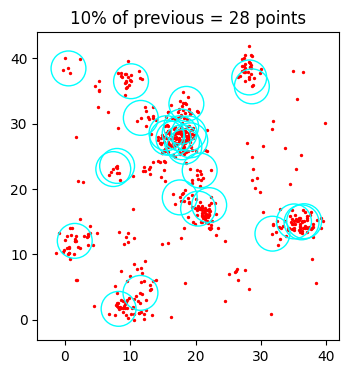

28


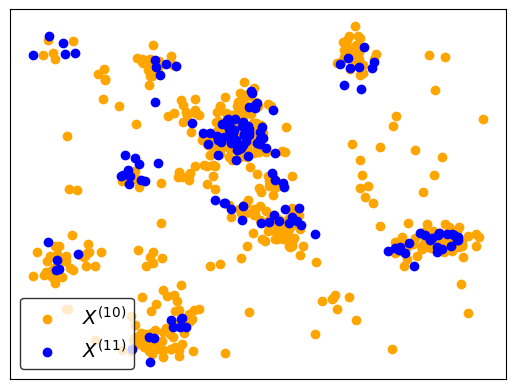

In [47]:
rng = np.random.default_rng()

n_parent = len(xy_parent)  # original parent have 74
size = rng.poisson(n_parent)  # random new n_parents 
lam = 5
n_children = rng.poisson(lam=lam, size=size)  # random children per parent, after lam number

len(n_children), n_children

# set parent location 
x_parent = rng.uniform(0,40, size)
y_parent = rng.uniform(0,40, size)

outx = np.concatenate(x_history).ravel().tolist() # special way to get a list from array
outy = np.concatenate(y_history).ravel().tolist()

plt.scatter(x_parent, y_parent)
plt.title('Parents')

# Plot iterplot
save_points={}
maxiter = 11
for i in range(maxiter):
    outx, outy = iter_poisson_unif_pic(outx, outy, r_survive=8, iter=i)
    save_points[i] = [outx,outy]

done


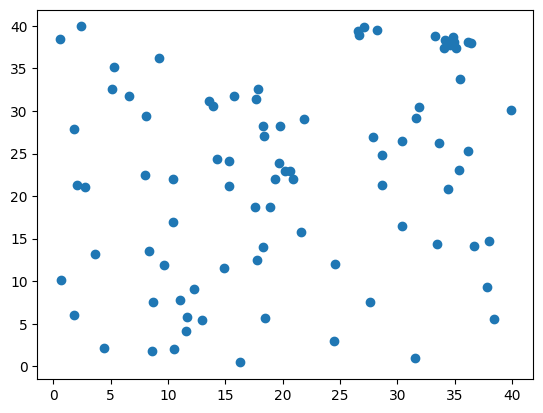

In [17]:
import pandas as pd 
np.array(save_points[0]).shape

np.array(save_points[0])[1]
slic = [10]
snip_p = np.vstack([np.array(save_points[0])[0], np.array(save_points[0])[1]]).T

plt.scatter(snip_p[:,0], snip_p[:,1])

for i in slic:
    snip_pdata = np.vstack([np.array(save_points[i])[0], np.array(save_points[i])[1]]).T
    df = pd.DataFrame(snip_pdata)
    df.rename(columns={0: 'x', 1: 'y'}, inplace=True)
    df

    df.to_csv(f'/Users/alexander/Chalmers/MVEX11-25-18/dataframes/path/unif-100iter{i}-aut.csv', index=False, header=False)

print('done')



In [18]:
df.rename(columns={0: 'x', 1: 'y'}, inplace=True)
df


,x,y
0,15.332939,24.175208
1,15.759116,31.746370
2,9.654016,11.853964
3,18.905295,18.672260
4,18.403847,27.024998
...,...,...
802,28.645927,40.298197
803,27.225245,40.406175
804,28.193814,40.735231
805,29.943398,38.699392


In [22]:
## Ändra iterativ till att ta random föräldrar
from numpy import linalg as LA

def iter_poisson_unif(outx, outy, lam=5, r_survive=3, iter=0):
    all_points = np.vstack([outx, outy]).T
    # outx = np.array(outx)
    # outy = np.array(outy)
    x_history=[outx]
    y_history=[outy]

    r_density_survive = r_survive  # default 3 

    count_all = np.array([np.sum(LA.norm((all_points - origin_p), axis=1) <= r_density_survive) for origin_p in all_points])  # take points that survive 
    count_all = count_all - 1  # exclude self
    print(all_points.shape[0]) # should grow, do point accounting
    # count_survive = all_points.shape[0]*0.1  # antal % som överlever
    # survive_point = heapq.nlargest(int(count_survive), enumerate(count_all.astype(int)), key=lambda x: x[1])
    # index=np.array(survive_point)[:,0]
    
    size_unif = int(np.array(outx).shape[0]*0.05)
    index = np.random.randint(0,all_points.shape[0], size=size_unif)  # 
    print(index)



    # plt.figure(figsize=(4, 4))
    # plt.scatter(all_points[:, 0], all_points[:, 1], color='red', marker='o', s=2)

    # fig = plt.gcf()
    # ax = fig.gca()

    # for i in index:
    #     circle2 = plt.Circle(all_points[i], r_density_survive/3, color='cyan', lw=1, fill=False)
    #     ax.add_patch(circle2)

    # ax.set_aspect('equal', 'box')
    # ax.set_title(f'10% of previous = {index.shape[0]} points')  # use to deduce what lambda should be 

    # plt.show() # take away 
    
    # broadcast the new points into next model 
    x_new_10_parent = [all_points[index][:,0]]  # picks the index points to generate new children
    y_new_10_parent = [all_points[index][:,1]]

    outx = np.concatenate(x_new_10_parent).ravel().tolist()
    outy = np.concatenate(y_new_10_parent).ravel().tolist()
    new_x = np.array(outx)
    new_y = np.array(outy)
    
    # plt.scatter(all_points[:,0], all_points[:,1], color='orange', label='previous') # take away

    # print(new_y.shape[0]) # take away comments 
    n_children = rng.poisson(lam=lam, size=new_y.shape[0])  # lam = 5 change above, gets new children for new parents 
    for i in range(new_y.shape[0]):
        x_child = rng.normal(new_x[i], size=n_children[i])
        y_child = rng.normal(new_y[i], size=n_children[i])
        x_history.append(x_child)  # add the children to x_history/y_history
        y_history.append(y_child)
        # if i == 0:
        #     plt.scatter(x_child, y_child, color='blue', label='new generated')  # only one legend
        # else:
        #     plt.scatter(x_child, y_child, color='blue')

    # plt.title(f'Iterative, step {iter}')
    # plt.legend(loc='best')
    
    outx = np.concatenate(x_history).ravel().tolist() # special way to get a list from array
    outy = np.concatenate(y_history).ravel().tolist()
    
    # remove 
    # plt.savefig(f'/Users/alexander/Chalmers/MVEX11-25-18/python-fig/uinf-iterative{iter}-model.png', format='png', bbox_inches='tight')
    # fig.savefig(f'/Users/alexander/Chalmers/MVEX11-25-18/python-fig/uinf-inspiration{iter}-iterative.png', format='png', bbox_inches='tight')  # prior inspiration 
    
    return outx, outy


outx0 = np.concatenate(x_history).ravel().tolist() # special way to get a list from array
outy0 = np.concatenate(y_history).ravel().tolist()
outx1, outy1 = iter_poisson_unif(outx0, outy0, r_survive=8, iter=1)

74
[20 10  3]


74
[64 50 42]
93
[18 81 26  6]
108
[64 75  6 90 50]
122
[ 95  38  28  50  82 102]
147
[ 55 111 137 134 102 116 105]
175
[  1  13  37   8 114 100 115 108]
208
[ 23   1 118 203 185 175  25  44  94  90]
251
[230 144  64  44  14  65 245 133   7 159  55 198]
308
[296 198 208   1  14   4 117  88 225  58 171   6 272 287   3]
392
[ 98  26 161 101 184 248  13 229 278 233 321 367 363 149  10 377  66 301
 274]
491
[207 187 276 377 133 410 357 169  69  43 103 452 315 250  15 236 255 226
 239 359 111 167 261 338]
74
[62  6 36]
82
[33  5 30 72]
109
[ 18 102  58  75  20]
132
[ 81  23 122  29 130 128]
161
[ 57 158  66 132  50 139  15 143]
200
[102 151   7  21  76  27  15 117  63 154]
254
[244 145 201 115 244 203 107  88 128  76 104 185]
307
[ 20  95  30 184 204  61 113  80 260 106 147  60 135 232  22]
402
[101 253 192 395  42 323 226  40  76   9  84 270 395  57  71 247 296 140
 348 236]
496
[204  99 201 453 167 423 485 444 314 317 166  81 232  78 326 364 494 465
 237 238 487 420 127 401]
633
[ 67 582 

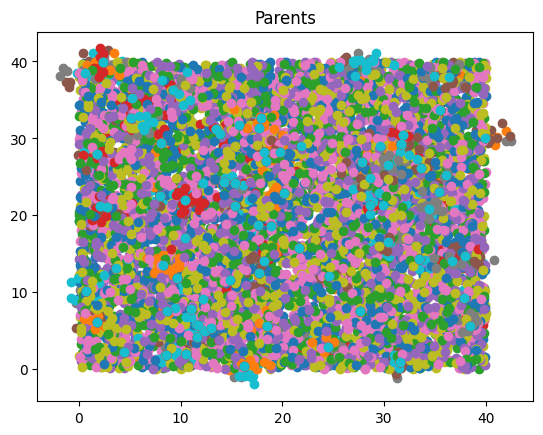

In [25]:
rng = np.random.default_rng()

for j in range(100):
    n_parent = len(xy_parent)  # original parent have 74
    size = rng.poisson(n_parent)  # random new n_parents 
    lam = 5
    n_children = rng.poisson(lam=lam, size=size)  # random children per parent, after lam number

    len(n_children), n_children

    # set parent location 
    x_parent = rng.uniform(0,40, size)
    y_parent = rng.uniform(0,40, size)

    outx = np.concatenate(x_history).ravel().tolist() # special way to get a list from array
    outy = np.concatenate(y_history).ravel().tolist()

    plt.scatter(x_parent, y_parent)
    plt.title('Parents')

    # Plot iterplot
    save_points={}
    maxiter = 11
    for i in range(maxiter):
        outx, outy = iter_poisson_unif(outx, outy, r_survive=8, iter=i)
        save_points[i] = [outx,outy]
        
    import pandas as pd 
    np.array(save_points[0]).shape

    np.array(save_points[0])[1]
    slic = [10]
    snip_p = np.vstack([np.array(save_points[0])[0], np.array(save_points[0])[1]]).T

    plt.scatter(snip_p[:,0], snip_p[:,1])

    for i in slic:
        snip_pdata = np.vstack([np.array(save_points[i])[0], np.array(save_points[i])[1]]).T
        df = pd.DataFrame(snip_pdata)
        df.rename(columns={0: 'x', 1: 'y'}, inplace=True)

        df.to_csv(f'/Users/alexander/Chalmers/MVEX11-25-18/dataframes/path/unif-100iter{j}-aut.csv', index=False, header=False)

print('done')



done


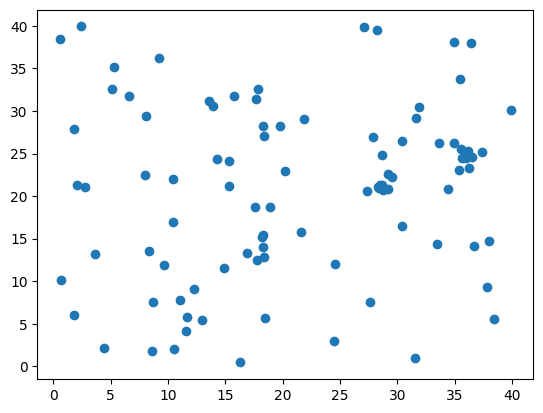

In [24]:
import pandas as pd 
np.array(save_points[0]).shape

np.array(save_points[0])[1]
slic = [10]
snip_p = np.vstack([np.array(save_points[0])[0], np.array(save_points[0])[1]]).T

plt.scatter(snip_p[:,0], snip_p[:,1])

for i in slic:
    snip_pdata = np.vstack([np.array(save_points[i])[0], np.array(save_points[i])[1]]).T
    df = pd.DataFrame(snip_pdata)
    df.rename(columns={0: 'x', 1: 'y'}, inplace=True)

    df.to_csv(f'/Users/alexander/Chalmers/MVEX11-25-18/dataframes/path/unif-100iter{i}-aut.csv', index=False, header=False)

print('done')

